# Matrix Factorization SVD


## 0 — Imports & Data

In [ ]:
from surprise import Dataset, SVD, accuracy, model_selection, Reader

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split


In [ ]:
path = "/Users/kiradavidoff/code/quantum_correlations/ml-100k"

ratings = pd.read_csv(
    f"{path}/u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"]
)

print(f"Ratings: {len(ratings):,}")
print(f"Users:   {ratings['user_id'].nunique()}")
print(f"Movies:  {ratings['item_id'].nunique()}")
print(f"Mean rating: {ratings['rating'].mean():.4f}")

ratings.head()


Ratings: 100,000
Users:   943
Movies:  1682
Mean rating: 3.5299


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [179]:
1682*943

1586126

In [ ]:
#  Index maps for PyTorch
user_ids  = ratings["user_id"].unique()
movie_ids = ratings["item_id"].unique()

user_to_idx  = {u: i for i, u in enumerate(user_ids)}
movie_to_idx = {m: i for i, m in enumerate(movie_ids)}

ratings["user_idx"]  = ratings["user_id"].map(user_to_idx)
ratings["movie_idx"] = ratings["item_id"].map(movie_to_idx)

n_users  = len(user_ids)
n_movies = len(movie_ids)
global_mean = float(ratings["rating"].mean())

# Shared train/test split
train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=42)

# PyTorch tensors
train_users   = torch.tensor(train_df["user_idx"].values,  dtype=torch.long)
train_movies  = torch.tensor(train_df["movie_idx"].values, dtype=torch.long)
train_ratings = torch.tensor(train_df["rating"].values,    dtype=torch.float32)

test_users    = torch.tensor(test_df["user_idx"].values,   dtype=torch.long)
test_movies   = torch.tensor(test_df["movie_idx"].values,  dtype=torch.long)
test_ratings  = torch.tensor(test_df["rating"].values,     dtype=torch.float32)

print("Train size:", len(train_df))
print("Test size: ", len(test_df))


Train size: 80000
Test size:  20000


## I — Data 

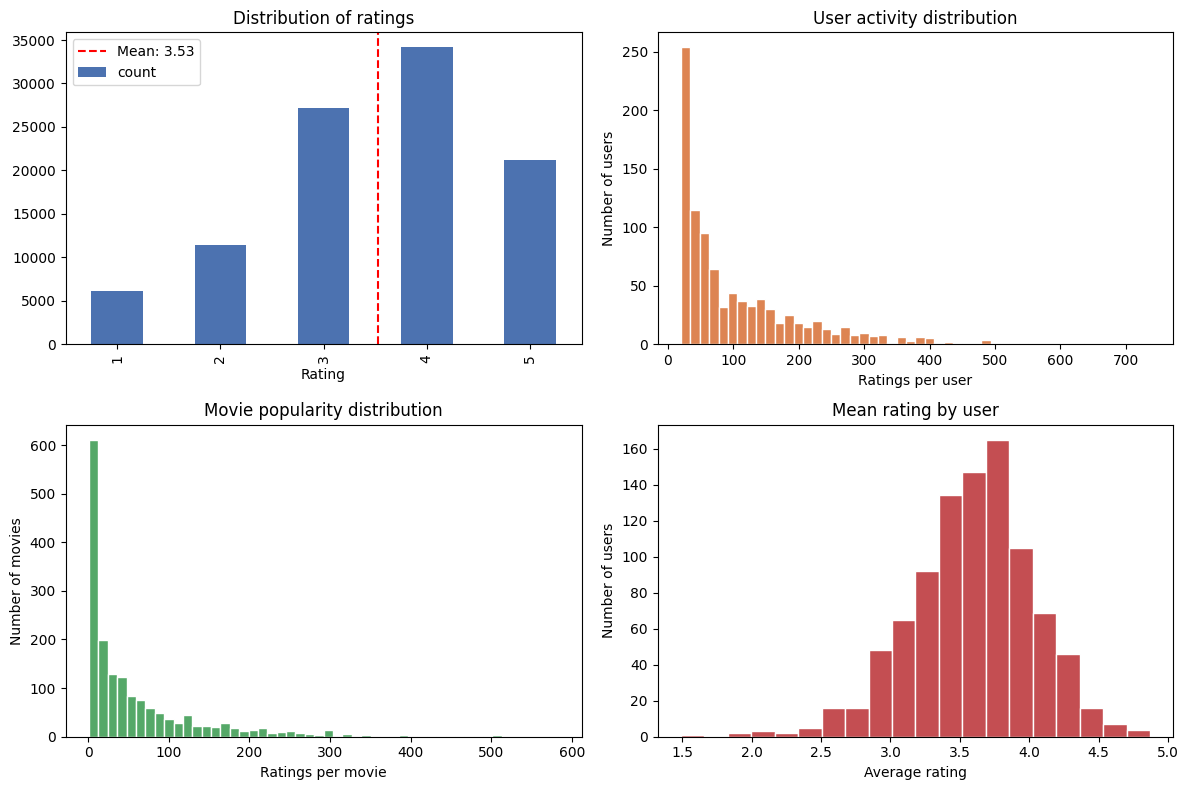

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Rating distribution
ax = axes[0, 0]
ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0")
ax.axvline(ratings["rating"].mean() - 1, color="red", linestyle="--",
           label=f'Mean: {ratings["rating"].mean():.2f}')
ax.set_title("Distribution of ratings")
ax.set_xlabel("Rating")
ax.legend()

# User activity
ax = axes[0, 1]
user_activity = ratings.groupby("user_id").size()
ax.hist(user_activity, bins=50, color="#DD8452", edgecolor="white")
ax.set_title("User activity distribution")
ax.set_xlabel("Ratings per user")
ax.set_ylabel("Number of users")

# Movie popularity
ax = axes[1, 0]
movie_popularity = ratings.groupby("item_id").size()
ax.hist(movie_popularity, bins=50, color="#55A868", edgecolor="white")
ax.set_title("Movie popularity distribution")
ax.set_xlabel("Ratings per movie")
ax.set_ylabel("Number of movies")

# Mean rating per user
ax = axes[1, 1]
user_mean = ratings.groupby("user_id")["rating"].mean()
ax.hist(user_mean, bins=20, color="#C44E52", edgecolor="white")
ax.set_title("Mean rating by user")
ax.set_xlabel("Average rating")
ax.set_ylabel("Number of users")

plt.tight_layout()
plt.show()


---
## II — Model I: Surprise SVD

Surprise's built-in SVD implements biased matrix factorisation:

$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$$




In [ ]:
reader = Reader(rating_scale=(1, 5))

train_data = Dataset.load_from_df(
    train_df[["user_id", "item_id", "rating"]],
    reader
)

trainset_s = train_data.build_full_trainset()

testset_s = list(
    test_df[["user_id", "item_id", "rating"]]
    .itertuples(index=False, name=None)
)


model_surprise = SVD(
    n_factors=50,
    n_epochs=30,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

model_surprise.fit(trainset_s)
predictions_s = model_surprise.test(testset_s)

rmse_surprise = accuracy.rmse(predictions_s)
mae_surprise  = accuracy.mae(predictions_s)
print(f"Surprise SVD  →  RMSE: {rmse_surprise:.4f}  MAE: {mae_surprise:.4f}")


RMSE: 0.9355
MAE:  0.7345
Surprise SVD  →  RMSE: 0.9355  MAE: 0.7345


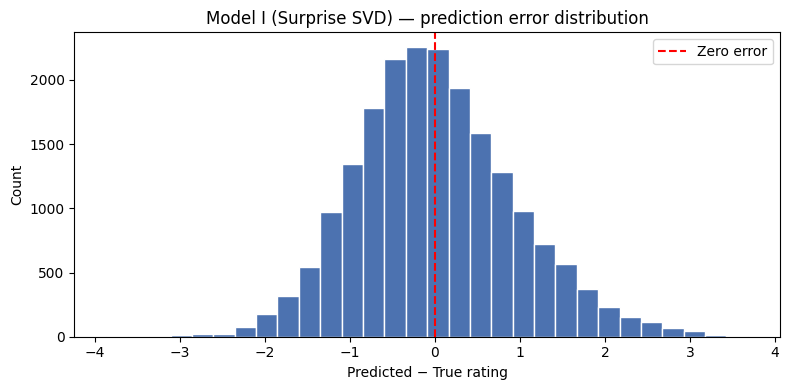

In [6]:
# Error distribution
pred_df = pd.DataFrame(predictions_s)
pred_df["error"] = pred_df["est"] - pred_df["r_ui"]

plt.figure(figsize=(8, 4))
plt.hist(pred_df["error"], bins=30, color="#4C72B0", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="Zero error")
plt.xlabel("Predicted − True rating")
plt.ylabel("Count")
plt.title("Model I (Surprise SVD) — prediction error distribution")
plt.legend()
plt.tight_layout()
plt.show()


---
## III — Model II: PyTorch SVD


$$\mathcal{L} = \sum_{(u,i)\in\kappa}(r_{ui}-\hat r_{ui})^2 + \lambda\left(\|p_u\|^2+\|q_i\|^2+b_u^2+b_i^2\right)$$

**Reference:** Y. Koren, R. Bell, and C. Volinsky, *Matrix Factorization Techniques for Recommender Systems*, Computer, 2009. DOI: https://doi.org/10.1109/MC.2009.263


In [ ]:
class MatrixFactorization(nn.Module):
    """
    Biased Matrix Factorisation — mirrors Surprise SVD exactly.

    Formula:  r_hat = mu + b_u + b_i + p_u · q_i

    Parameters
    ----------
    n_users     : number of unique users  → rows of P
    n_movies    : number of unique movies → rows of Q
    n_factors   : latent dimension k
    rating_mean : dataset mean, used to fix global bias mu
    """

    def __init__(self, n_users, n_movies, n_factors=50, rating_mean=train_df["rating"].mean()):
        super().__init__()

        # P — user latent factors
        self.user_factors  = nn.Embedding(n_users,  n_factors)
        # Q — item latent factors
        self.movie_factors = nn.Embedding(n_movies, n_factors)

        # b_u —  user bias
        self.user_bias  = nn.Embedding(n_users,  1)

        # b_i — item bias
        self.movie_bias = nn.Embedding(n_movies, 1)

        # mu — global mean rating, fixed
        self.register_buffer("global_bias", torch.tensor(rating_mean, dtype=torch.float32))

        # small random init for factors, zero for biases
        nn.init.normal_(self.user_factors.weight,  std=0.01)
        nn.init.normal_(self.movie_factors.weight, std=0.01)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, users, movies):
        p_u = self.user_factors(users)
        q_i = self.movie_factors(movies)

        dot = (p_u * q_i).sum(dim=1)

        b_u = self.user_bias(users).squeeze(-1)
        b_i = self.movie_bias(movies).squeeze(-1)

        # r_hat = mu + b_u + b_i + p_u · q_i
        return self.global_bias + b_u + b_i + dot


In [ ]:
def explicit_loss(pred, target, model, users, movies, lam=0.02):
    """
    Regularised MSE — explicit version of Surprise's internal objective.

    L = (1/N) * sum((r - r_hat)^2) + lambda * (||p_u||^2 + ||q_i||^2 + b_u^2 + b_i^2)
    """
    # reconstruction error
    mse = ((pred - target) ** 2).mean()

    # regularisation term
    p_u = model.user_factors(users)
    q_i = model.movie_factors(movies)
    b_u = model.user_bias(users).squeeze(-1)
    b_i = model.movie_bias(movies).squeeze(-1)

    reg = lam * (
        (p_u ** 2).mean() +
        (q_i ** 2).mean() +
        (b_u ** 2).mean() +
        (b_i ** 2).mean()
    )

    return mse + reg


In [ ]:
# Train
model_pytorch = MatrixFactorization(
    n_users, n_movies,
    n_factors=50,
    rating_mean=global_mean
)

# optimizer = torch.optim.SGD(model_pytorch.parameters(), lr=0.005)
optimizer = torch.optim.Adam(model_pytorch.parameters(), lr=0.001)
epochs = 180
lam    = 0.002

for epoch in range(epochs):
    model_pytorch.train()
    optimizer.zero_grad()

    preds = model_pytorch(train_users, train_movies)
    loss  = explicit_loss(preds, train_ratings, model_pytorch,
                          train_users, train_movies, lam=lam)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Loss: {loss.item():.4f}")


Epoch   5/180 | Loss: 1.2613
Epoch  10/180 | Loss: 1.2524
Epoch  15/180 | Loss: 1.2426
Epoch  20/180 | Loss: 1.2315
Epoch  25/180 | Loss: 1.2188
Epoch  30/180 | Loss: 1.2042
Epoch  35/180 | Loss: 1.1873
Epoch  40/180 | Loss: 1.1680
Epoch  45/180 | Loss: 1.1463
Epoch  50/180 | Loss: 1.1224
Epoch  55/180 | Loss: 1.0964
Epoch  60/180 | Loss: 1.0689
Epoch  65/180 | Loss: 1.0404
Epoch  70/180 | Loss: 1.0115
Epoch  75/180 | Loss: 0.9827
Epoch  80/180 | Loss: 0.9545
Epoch  85/180 | Loss: 0.9273
Epoch  90/180 | Loss: 0.9013
Epoch  95/180 | Loss: 0.8765
Epoch 100/180 | Loss: 0.8529
Epoch 105/180 | Loss: 0.8304
Epoch 110/180 | Loss: 0.8090
Epoch 115/180 | Loss: 0.7884
Epoch 120/180 | Loss: 0.7686
Epoch 125/180 | Loss: 0.7495
Epoch 130/180 | Loss: 0.7310
Epoch 135/180 | Loss: 0.7131
Epoch 140/180 | Loss: 0.6957
Epoch 145/180 | Loss: 0.6788
Epoch 150/180 | Loss: 0.6623
Epoch 155/180 | Loss: 0.6461
Epoch 160/180 | Loss: 0.6304
Epoch 165/180 | Loss: 0.6150
Epoch 170/180 | Loss: 0.5999
Epoch 175/180 

In [ ]:
# Evaluate
model_pytorch.eval()
with torch.no_grad():
    test_preds_pt = model_pytorch(test_users, test_movies)
    rmse_pytorch  = torch.sqrt(((test_preds_pt - test_ratings) ** 2).mean()).item()

print(f"Model II (PyTorch)  →  RMSE: {rmse_pytorch:.4f}")
print(f"Model I  (Surprise) →  RMSE: {rmse_surprise:.4f}")


Model II (PyTorch)  →  RMSE: 0.9391
Model I  (Surprise) →  RMSE: 0.9390


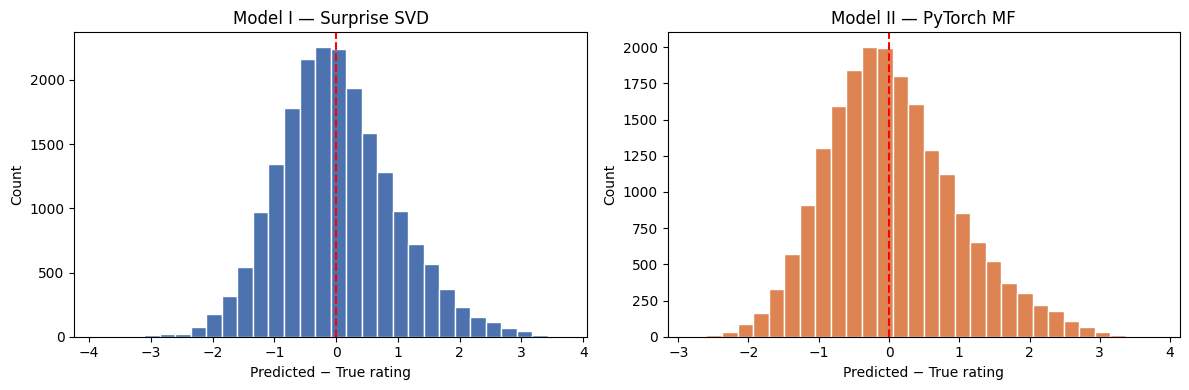

In [11]:
# Error distribution comparison
pt_errors = (test_preds_pt - test_ratings).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, errors, title, color in zip(
    axes,
    [pred_df["error"].values, pt_errors],
    ["Model I — Surprise SVD", "Model II — PyTorch MF"],
    ["#4C72B0", "#DD8452"]
):
    ax.hist(errors, bins=30, color=color, edgecolor="white")
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted − True rating")
    ax.set_ylabel("Count")
    ax.set_title(title)

plt.tight_layout()
plt.show()


## IV- SVD with MSE as Loss

$$\mathcal{L} = \sum_{(u,i)\in\kappa}(r_{ui}-\hat r_{ui})^2$$


In [12]:
model = MatrixFactorization(
    n_users,
    n_movies,
    n_factors=50,
    rating_mean=train_df["rating"].mean()
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 185

loss_fn = nn.MSELoss()

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    preds = model(train_users, train_movies)

    loss = loss_fn(preds, train_ratings)

    loss.backward()
    optimizer.step()

    if epoch % 5 == 0:
        print(f"Epoch {epoch:3d} | Loss = {loss.item():.4f}")

Epoch   0 | Loss = 1.2681
Epoch   5 | Loss = 1.2596
Epoch  10 | Loss = 1.2505
Epoch  15 | Loss = 1.2406
Epoch  20 | Loss = 1.2293
Epoch  25 | Loss = 1.2164
Epoch  30 | Loss = 1.2016
Epoch  35 | Loss = 1.1846
Epoch  40 | Loss = 1.1654
Epoch  45 | Loss = 1.1438
Epoch  50 | Loss = 1.1200
Epoch  55 | Loss = 1.0942
Epoch  60 | Loss = 1.0669
Epoch  65 | Loss = 1.0385
Epoch  70 | Loss = 1.0095
Epoch  75 | Loss = 0.9804
Epoch  80 | Loss = 0.9517
Epoch  85 | Loss = 0.9237
Epoch  90 | Loss = 0.8967
Epoch  95 | Loss = 0.8708
Epoch 100 | Loss = 0.8459
Epoch 105 | Loss = 0.8222
Epoch 110 | Loss = 0.7995
Epoch 115 | Loss = 0.7777
Epoch 120 | Loss = 0.7568
Epoch 125 | Loss = 0.7368
Epoch 130 | Loss = 0.7174
Epoch 135 | Loss = 0.6987
Epoch 140 | Loss = 0.6806
Epoch 145 | Loss = 0.6631
Epoch 150 | Loss = 0.6461
Epoch 155 | Loss = 0.6296
Epoch 160 | Loss = 0.6134
Epoch 165 | Loss = 0.5977
Epoch 170 | Loss = 0.5824
Epoch 175 | Loss = 0.5675
Epoch 180 | Loss = 0.5529


In [ ]:
# Evaluate
model.eval()
with torch.no_grad():
    mse_test_preds = model(test_users, test_movies)
    mse_rmse = torch.sqrt(((mse_test_preds - test_ratings) ** 2).mean())

print(f"Model III (MSE)  →  RMSE: {mse_rmse:.4f}")
print(f"Model II (regularized loss)  →  RMSE: {rmse_pytorch:.4f}")
print(f"Model I  (Surprise) →  RMSE: {rmse_surprise:.4f}")

Model III (MSE)  →  RMSE: 0.9396
Model II (PyTorch)  →  RMSE: 0.9391
Model I  (Surprise) →  RMSE: 0.9390


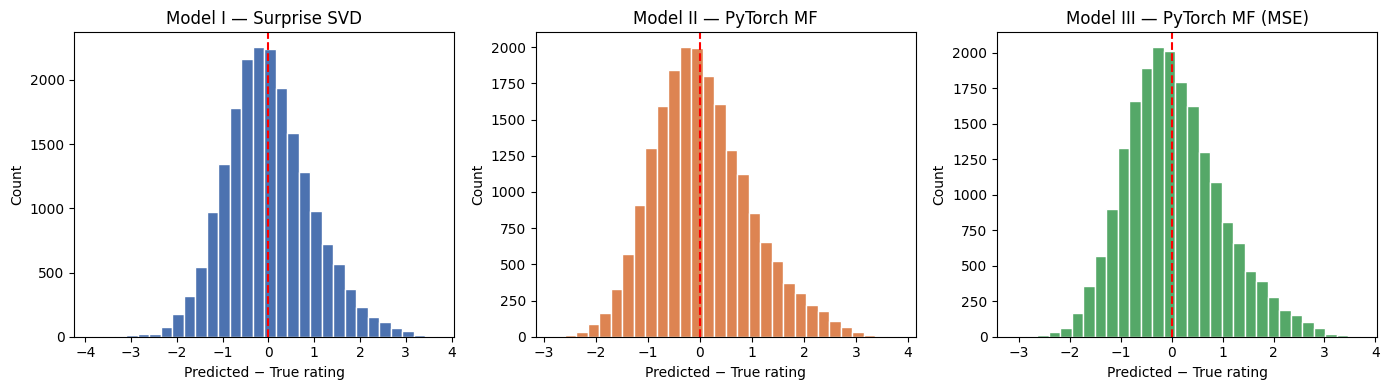

In [14]:
# Error distribution comparison
mse_errors = (mse_test_preds - test_ratings).numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, errors, title, color in zip(

    axes,
    [pred_df["error"].values,pt_errors, mse_errors],
    ["Model I — Surprise SVD", "Model II — PyTorch MF", "Model III — PyTorch MF (MSE)"],
    ["#4C72B0", "#DD8452", "#55A868"]
):
    ax.hist(errors, bins=30, color=color, edgecolor="white")
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted − True rating")
    ax.set_ylabel("Count")
    ax.set_title(title)

plt.tight_layout()
plt.show()


---
## V — Prediction as probability
Softmax (predictions)


In [40]:
model_pytorch.eval()

n_movies = len(movie_to_idx)
movie_ids = torch.arange(n_movies)
all_probs = {}

with torch.no_grad():

    for user_idx in test_df["user_idx"].unique():

        users = torch.full(
            (n_movies,),
            user_idx,
            dtype=torch.long
        )

        scores = model_pytorch(users, movie_ids)

        probs = torch.softmax(scores, dim=0)

        all_probs[user_idx] = probs.cpu()

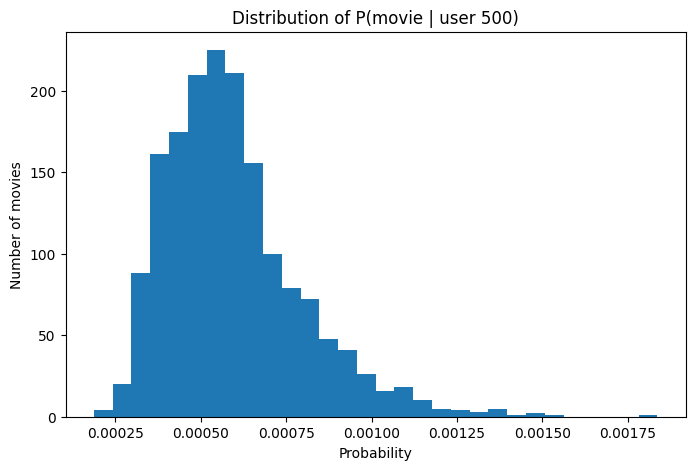

In [54]:
plt.figure(figsize=(8, 5))

plt.hist(
    all_probs[500].numpy(),
    bins=30
)

plt.xlabel("Probability")
plt.ylabel("Number of movies")
plt.title(f"Distribution of P(movie | user {500})")

plt.show()


## Improvements ( To Do => SVD ++)